# Задача: Отобразить высокомерные данные $X ∈ ℝ^D$ в низкомерное пространство $Y ∈ ℝ^d (d=2,3)$ так, чтобы сохранить структуру соседства.

    1. Вероятностная постановка задачи


Задача: Отобразить высокомерные данные $X ∈ ℝ^D$ в низкомерное пространство $Y ∈ ℝ^d (d=2,3)$
так, чтобы сохранить структуру соседства.


        - Вероятности в исходном пространстве

Гауссово ядро для измерения сходства:

$
p_{j|i} = exp(-||x_i - x_j||^2 / (2σ_i^2)) / Σ_{k≠i} exp(-||x_i - x_k||^2 / (2σ_i^2))$

Симметризация вероятностей:

$
p_{ij} = (p_{j|i} + p_{i|j}) / (2n)$

Перплексия (perplexity) как гиперпараметр:

$
Perp(P_i) = 2^{H(P_i)}, $

где $H(P_i) = -Σ_j p_{j|i} log₂ p_{j|i}$

        - Вероятности в целевом пространстве

Распределение Стьюдента с одной степенью свободы:

$
q_{ij} = (1 + ||y_i - y_j||^2)^{-1} / Σ_{k≠l} (1 + ||y_k - y_l||^2)^{-1}$

Преимущества t-распределения:

       * Тяжелые хвосты

       * Устойчивость к проклятию размерности

       * Улучшенное разделение кластеров

       * Функция стоимости (KL-дивергенция)

$C(Y) = KL(P||Q) = Σ_i Σ_j p_{ij} log(p_{ij} / q_{ij})$

    2. Оптимизация функции стоимости

        2.1. Градиент функции стоимости

$∂C/∂y_i = 4 Σ_j (p_{ij} - q_{ij})(y_i - y_j)(1 + ||y_i - y_j||^2)^{-1}$

       2.2. Методы оптимизации

Градиентный спуск с моментумом:

$Y^{(t)} = Y^{(t-1)} + η ∂C/∂Y + α(t)(Y^{(t-1)} - Y^{(t-2)})$


Раннее преувеличение (early exaggeration):


$p_{ij} ← p_{ij} × 4 (первые 100 итераций)$


Адаптивное обучение (adaptive learning rate)

        2.3. Сложности оптимизации

            - Невыпуклость функции стоимости

            - Локальные минимумы

            - Чувствительность к начальной инициализации

            - Вычислительная сложность O(n²)

Импорт библиотек

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler, LabelEncoder


# Задание

1. Провести исследование влияния гиперпараметров на результаты кластеризации с T-SNE
2. Сравнить с PCA
   
Использовать 2 датасета - стандартного типа Ирис или Цифры, и своего. Не забываем про нормировку и eda в целом

In [3]:
# путь к вашему файлу
path = "/content/ObesityDataSet.csv"  # замените на реальный путь

df = pd.read_csv(path)
df.head()


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

In [5]:
df['NObeyesdad'].value_counts()

,count
NObeyesdad,
Obesity_Type_I,351
Obesity_Type_III,324
Obesity_Type_II,297
Overweight_Level_I,290
Overweight_Level_II,290
Normal_Weight,287
Insufficient_Weight,272


In [6]:
df.describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,24.312600,1.701677,86.586058,2.419043,2.685628,2.008011,1.010298,0.657866
std,6.345968,0.093305,26.191172,0.533927,0.778039,0.612953,0.850592,0.608927
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.947192,1.630000,65.473343,2.000000,2.658738,1.584812,0.124505,0.000000
50%,22.777890,1.700499,83.000000,2.385502,3.000000,2.000000,1.000000,0.625350
75%,26.000000,1.768464,107.430682,3.000000,3.000000,2.477420,1.666678,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


In [7]:
def _keep_top_classes(df: pd.DataFrame, target_col: str, n_classes: int) -> pd.DataFrame:
        """Топ n самых частых классов в датасете"""
        uniq = df[target_col].nunique()
        if n_classes >= uniq:
            return df

        top = df[target_col].value_counts().head(n_classes).index
        trimmed = df[df[target_col].isin(top)]
        return trimmed

def _make_preprocessor(numeric_cols: list[str], cat_cols: list[str]) -> ColumnTransformer:
      """Преобразование числовых и категориальных признаков."""
      return ColumnTransformer(
          transformers=[
              ("num", StandardScaler(), numeric_cols),
              ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_cols),
          ]
      )

In [8]:
from sklearn.preprocessing import LabelEncoder

n_classes = 4  # поставьте 7, если хотите сохранить все классы ожирения из датасета
df = _keep_top_classes(df, target_col="NObeyesdad", n_classes=int(n_classes))

X_raw = df.drop(columns=["NObeyesdad"])
y_raw = df["NObeyesdad"]

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_raw)
class_names = label_encoder.classes_

print(f"Классы: {class_names}")

numerical_features = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE"]
categorical_features = [
    "Gender", "family_history_with_overweight", "FAVC",
    "CAEC", "SMOKE", "SCC", "CALC", "MTRANS"
]

preprocessor = _make_preprocessor(numerical_features, categorical_features)
X_transformed = preprocessor.fit_transform(X_raw)

cat_encoder = preprocessor.named_transformers_["cat"]
cat_feature_names = cat_encoder.get_feature_names_out(categorical_features)
feature_names = numerical_features + list(cat_feature_names)


Классы: ['Obesity_Type_I' 'Obesity_Type_II' 'Obesity_Type_III'
 'Overweight_Level_I']


In [9]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

iris = load_iris()
X_iris = iris.data
y_iris = iris.target
iris_names = iris.target_names

scaler = StandardScaler()
X_iris_scaled = scaler.fit_transform(X_iris)

X_iris_scaled = X_iris_scaled
y_iris = y_iris

print(X_iris_scaled.shape, y_iris.shape)


(150, 4) (150,)


Разделить выборку на фичи и целевую переменную

In [10]:
feature_cols = 'NObeyesdad'
X = X_transformed
y = y_encoded

print(X.shape, y.shape)

(1262, 22) (1262,)


pca = PCA(n_components=2, random_state=42)

ожирение

Доля объяснённой дисперсии: [0.23408242 0.16286994] Суммарно: 0.39695235853456384


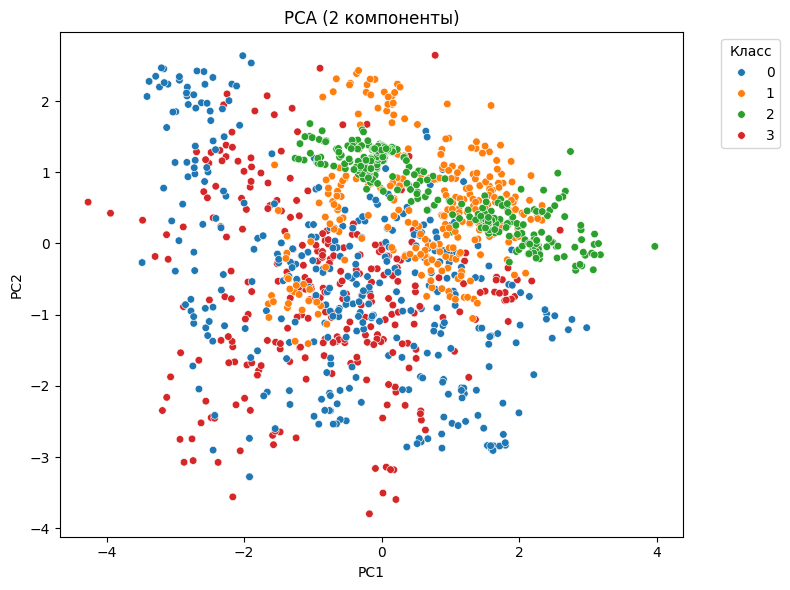

In [11]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

print("Доля объяснённой дисперсии:", pca.explained_variance_ratio_ ,
      "Суммарно:",  pca.explained_variance_ratio_.sum() )

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, palette="tab10", s=30)
plt.title("PCA (2 компоненты)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Класс", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


iris

Доля объяснённой дисперсии: [0.72962445 0.22850762] Суммарно: 0.9581320720000166


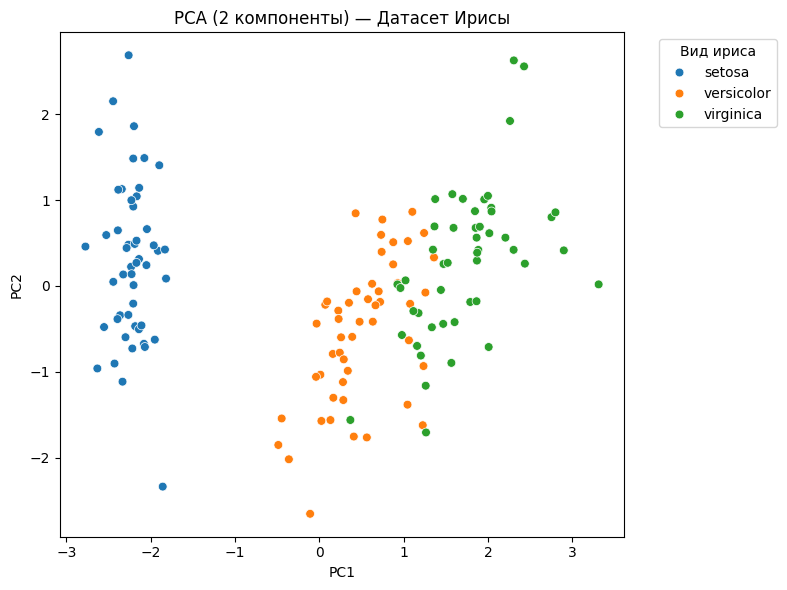

In [12]:
pca = PCA(n_components=2, random_state=42)
X_pca_iris = pca.fit_transform(X_iris_scaled)

print("Доля объяснённой дисперсии:", pca.explained_variance_ratio_,
      "Суммарно:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca_iris[:, 0], y=X_pca_iris[:, 1], hue=iris_names[y_iris], palette="tab10", s=40)
plt.title("PCA (2 компоненты) — Датасет Ирисы")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Вид ириса", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


TSNE 2 компоненты

ожирение

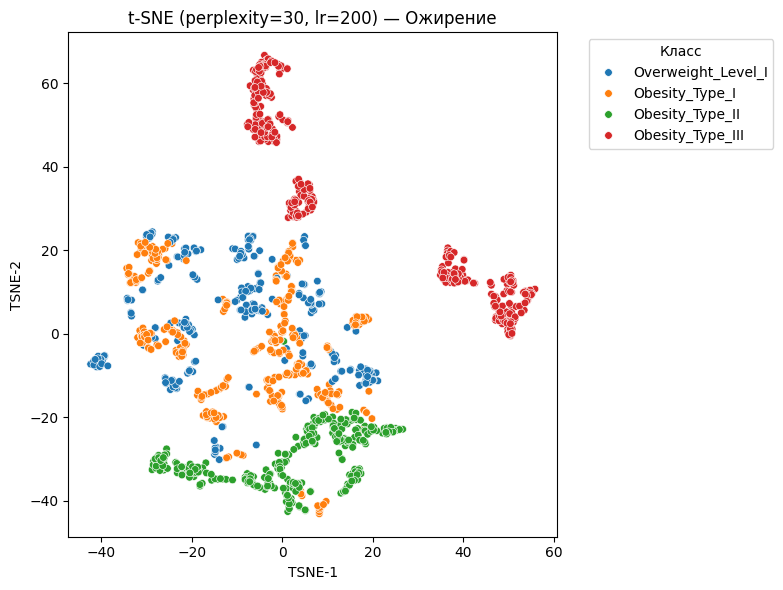

In [13]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate=200,
    random_state=42
)

X_tsne = tsne.fit_transform(X)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=class_names[y], palette="tab10", s=30)
plt.title("t-SNE (perplexity=30, lr=200) — Ожирение")
plt.xlabel("TSNE-1")
plt.ylabel("TSNE-2")
plt.legend(title="Класс", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()



iris

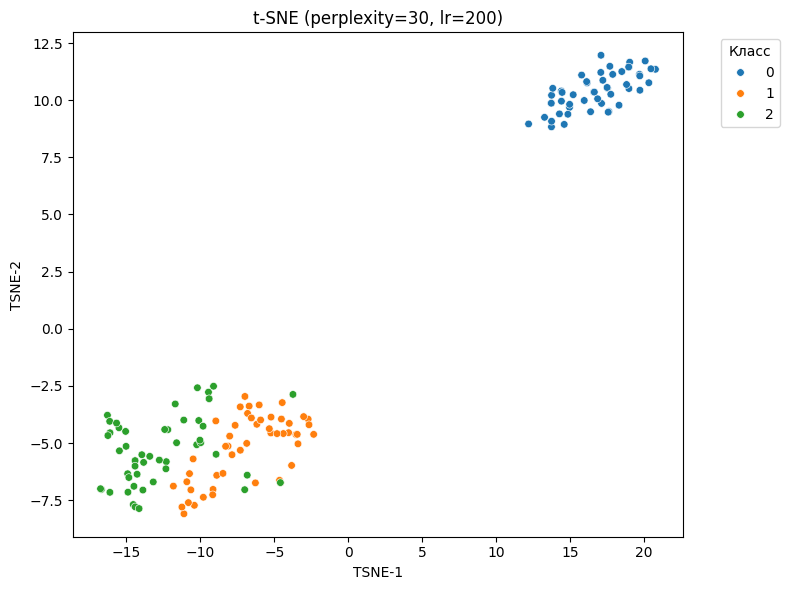

In [14]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    learning_rate=200
)

X_tsne_iris = tsne.fit_transform(X_iris_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_tsne_iris[:, 0], y=X_tsne_iris[:, 1], hue=y_iris, palette="tab10", s=30)
plt.title("t-SNE (perplexity=30, lr=200)")
plt.xlabel("TSNE-1")
plt.ylabel("TSNE-2")
plt.legend(title="Класс", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()



ожирение

In [15]:
from sklearn.metrics import pairwise_distances

def separation_score(X_2d, y):
    D = pairwise_distances(X_2d)
    same = D[y[:, None] == y[None, :]]
    diff = D[y[:, None] != y[None, :]]
    return same.mean(), diff.mean(), diff.mean() / same.mean()

pca_same, pca_diff, pca_ratio = separation_score(X_pca, y)
tsne_same, tsne_diff, tsne_ratio = separation_score(X_tsne, y)

print("PCA:  среднее расстояние внутри класса =", pca_same,
      ", между классами =", pca_diff,
      ", ratio =", pca_ratio)
print("t-SNE: среднее расстояние внутри класса =", tsne_same,
      ", между классами =", tsne_diff,
      ", ratio =", tsne_ratio)


PCA:  среднее расстояние внутри класса = 1.986415923189693 , между классами = 2.49453602471618 , ratio = 1.255797436777778
t-SNE: среднее расстояние внутри класса = 27.97046 , между классами = 47.88892 , ratio = 1.7121248


ирисы

In [16]:
pca_same_iris, pca_diff_iris, pca_ratio_iris = separation_score(X_pca_iris, y_iris)
tsne_same_iris, tsne_diff_iris, tsne_ratio_iris = separation_score(X_tsne_iris, y_iris)

print("PCA:  среднее расстояние внутри класса =", pca_same_iris,
      ", между классами =", pca_diff_iris,
      ", ratio =", pca_ratio_iris)
print("t-SNE: среднее расстояние внутри класса =", tsne_same_iris,
      ", между классами =", tsne_diff_iris,
      ", ratio =", tsne_ratio_iris)


PCA:  среднее расстояние внутри класса = 1.1544139208878488 , между классами = 3.0160279739751035 , ratio = 2.6126053397342135
t-SNE: среднее расстояние внутри класса = 3.511914 , между классами = 22.74013 , ratio = 6.4751387


Вычислить и отрисовать T-SNE с разным значением Perplexity

ожирение

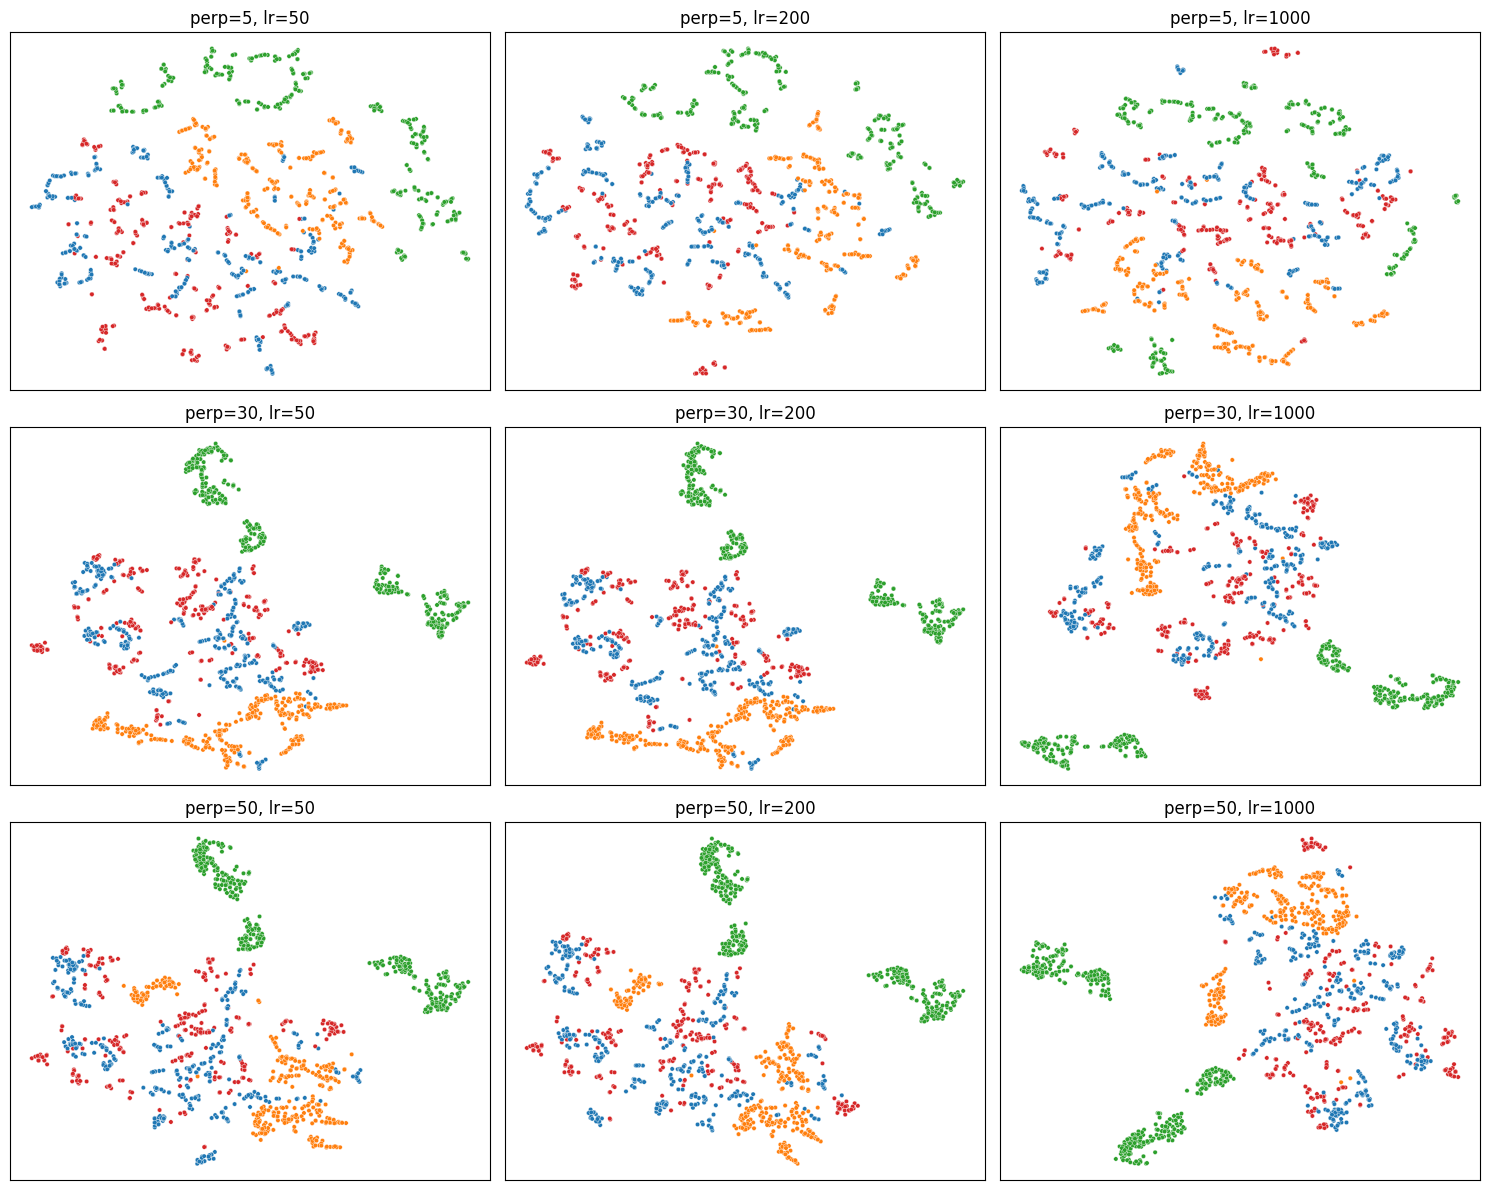

In [17]:
perplexities = [5, 30, 50]
learning_rates = [50, 200, 1000]

fig, axes = plt.subplots(len(perplexities), len(learning_rates),
                         figsize=(5*len(learning_rates), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(learning_rates):
        tsne = TSNE(
            perplexity=perp,
            learning_rate=lr,
            random_state=42
        )
        X_emb = tsne.fit_transform(X)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1],
                        hue=y, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"perp={perp}, lr={lr}")
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()


При больших значения perplexity явно различыми отдельные кластеры

небольшие изменения perplexity кластеры ращличимы, но более "разряжены" чем при больших

небольшие изменения learn rate практически не влияет на результат

ирисы

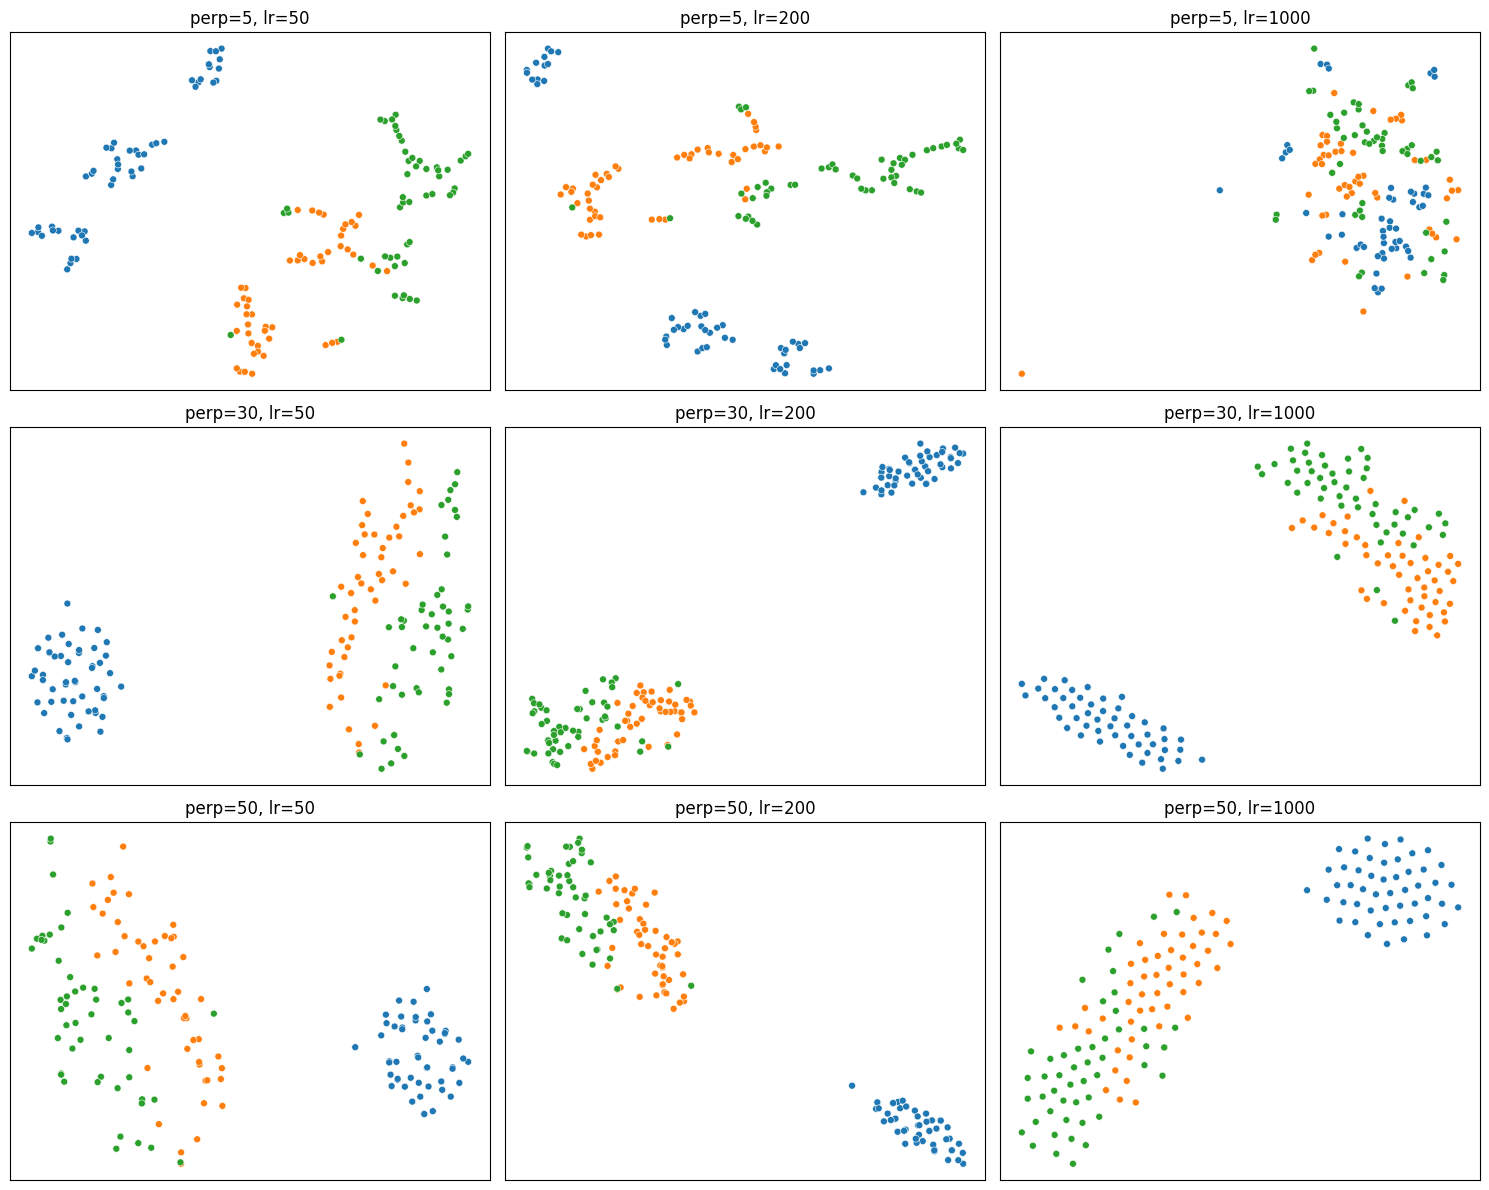

In [19]:
perplexities = [5, 30, 50]
learning_rates = [50, 200, 1000]

fig, axes = plt.subplots(len(perplexities), len(learning_rates),
                         figsize=(5*len(learning_rates), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(learning_rates):
        tsne = TSNE(
            perplexity=perp,
            learning_rate=lr,
            random_state=42
        )
        X_emb = tsne.fit_transform(X_iris_scaled)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1],
                        hue=y_iris, palette="tab10", s=25, ax=ax, legend=False)
        ax.set_title(f"perp={perp}, lr={lr}")
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()




При маленьких значениях perplexity кластеры "разряжены"

learning_rate влияет на результат только при больших значениях

При увеличении обоих параметров увеличивается расстояния между кластерами

Проанализируйте:

как меняется форма кластеров,

возникают ли “разрывы” или слияния при разных параметрах,

насколько стабилен рисунок при небольших изменениях параметров.

PCA: устойчивая структура
Для PCA параметров немного (по сути только число компонент), проекция при фиксированном random_state практически не меняется, что показывает устойчивость метода.

Можно показать, что при разных n_components (2, 3, больше) первые две компоненты остаются близкими, а общая структура мало меняется.

In [23]:
n_components = [i for i in range(2,6)]

ожирение

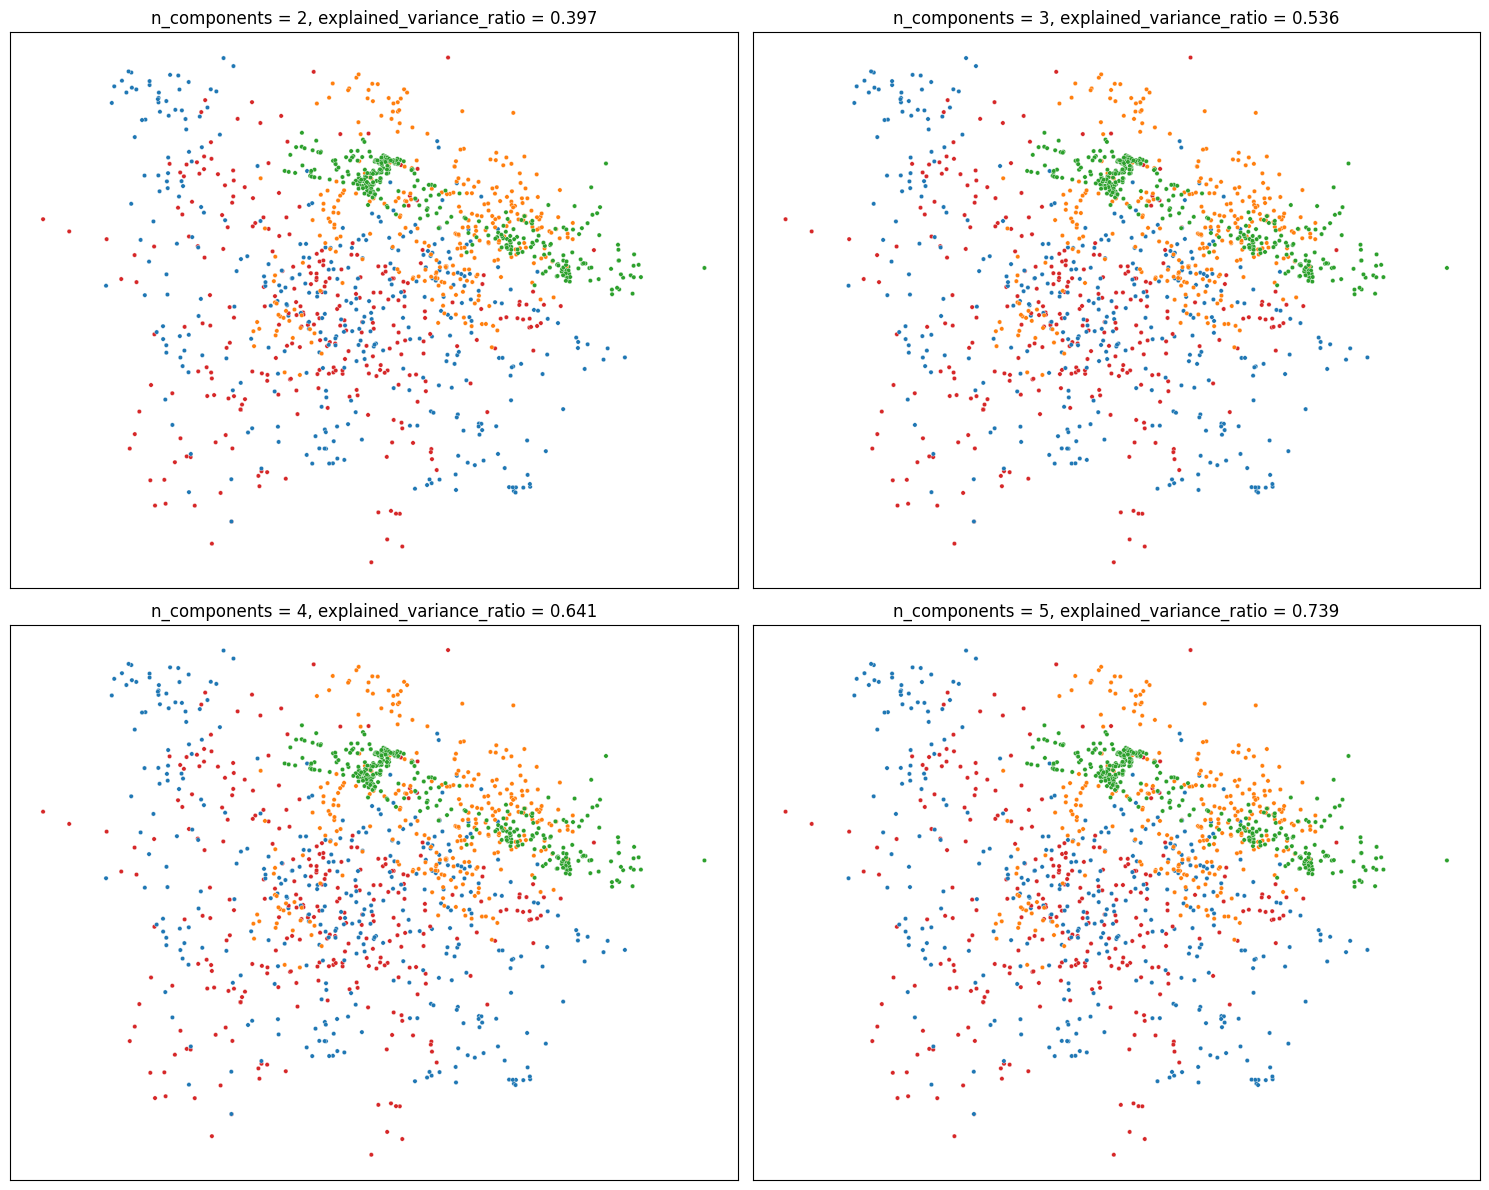

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

for i, n_comp in enumerate(n_components):
    pca = PCA(n_components=n_comp, random_state=42)
    X_pca = pca.fit_transform(X)
    ax = axes[i // 2, i % 2]
    sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1],
                    hue=y, palette="tab10", s=10, ax=ax, legend=False)
    ax.set_title(f"n_components = {n_comp}, explained_variance_ratio = {pca.explained_variance_ratio_.sum():.3f}")
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()



ирисы

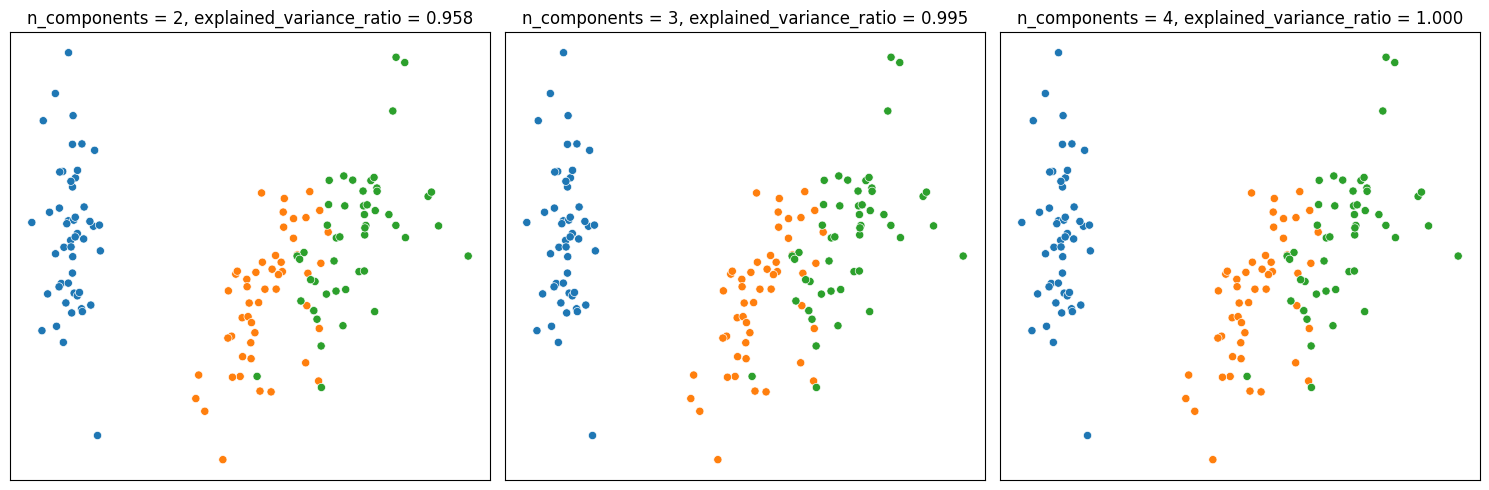

In [26]:
n_components_iris =  list(range(2, 5))
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, n_comp in enumerate(n_components_iris):
    pca = PCA(n_components=n_comp, random_state=42)
    X_pca_iris = pca.fit_transform(X_iris_scaled)
    ax = axes[i]
    sns.scatterplot(x=X_pca_iris[:, 0], y=X_pca_iris[:, 1],
                    hue=y_iris, palette="tab10", s=35, ax=ax, legend=False)
    ax.set_title(f"n_components = {n_comp}, explained_variance_ratio = {pca.explained_variance_ratio_.sum():.3f}")
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()
